# Do rule-based title features improve YouTube view predictions?

We predict `log_views` using Ridge regression. Our question is whether 14 title
features, such as title length, uppercase ratio, and exclamation mark count,
improve predictions beyond video age, channel baseline, category, and publication week.

We evaluate two settings: later videos from known channels and videos from unseen
channels. Within each setting, both models use the same training and test videos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from ytclickbait.config import load_config
from ytclickbait.rule_based_model_inputs import (
    merge_rule_inputs,
    score_rule_predictions,
)

## 1. Build the modeling dataset

Each row represents one video. We join video metadata and `log_views` from
`videos.parquet`, split assignments and channel baselines from `split.parquet`,
and 14 title features from `rule_features.parquet`.

The join uses `video_id`. Before merging, `merge_rule_inputs()` checks that the
three tables contain the same video IDs and that each ID appears once per table.

In [2]:
cfg = load_config()

videos = pd.read_parquet(cfg.file("videos"))
split = pd.read_parquet(cfg.file("split"))
rules = pd.read_parquet(cfg.file("rule_features"))

# Use the same merge function covered by the input validation tests.
df = merge_rule_inputs(videos, split, rules)
rule_cols = rules.columns.drop("video_id").tolist()

print(f"Modeling dataset: {len(df):,} videos, {len(rule_cols)} rule features")
display(df[["title", "log_views", "split_time", "n_exclaim", "caps_ratio"]].head())

Modeling dataset: 78,180 videos, 14 rule features


,title,log_views,split_time,n_exclaim,caps_ratio
0,Jadon Sancho • Magical Skills & Goals,12.979280,train,0,0.172414
1,Migos - Avalanche (Official Video),15.735846,excluded,0,0.148148
2,MY TESLA PAYS FOR ITSELF,13.245354,excluded,0,1.000000
3,Supporting Actress in a Comedy: 73rd Emmys,13.433679,train,0,0.121212
4,San Francisco 49ers vs. Arizona Cardinals Game...,14.478602,test,0,0.185185


## 2. Define the model comparison

For each split, we fit two Ridge models. The baseline uses four controls.
The second model adds the 14 title features. We keep the training rows, test
rows, preprocessing procedure, and Ridge settings the same within each split.

We report test RMSE on the log-view scale and test R². Lower RMSE and higher
R² indicate better predictions on the same test videos.

In [3]:
def compare_rule_models(train, test, channel_baseline_col, rule_cols):
    """Compare two Ridge models on the same training and test videos."""
    numeric_controls = ["log_age_days", channel_baseline_col]
    category_cols = ["category_name", "publish_week"]
    rows = []

    for model_name, extra_cols in [
        ("Controls only", []),
        ("Controls + 14 rule features", rule_cols),
    ]:
        numeric_cols = numeric_controls + extra_cols
        input_cols = numeric_cols + category_cols

        preprocess = ColumnTransformer([
            ("numeric", StandardScaler(), numeric_cols),
            ("category", OneHotEncoder(handle_unknown="ignore"), category_cols),
        ])

        # Fit preprocessing and Ridge using training videos only.
        model = make_pipeline(preprocess, Ridge(alpha=1.0, solver="lsqr"))
        model.fit(train[input_cols], train["log_views"])

        # Score predictions against the actual log views of the same test videos.
        predictions = model.predict(test[input_cols])
        scores = score_rule_predictions(test["log_views"], predictions)

        rows.append({
            "Model": model_name,
            "RMSE": scores["RMSE"],
            "R²": scores["R²"],
        })

    return pd.DataFrame(rows).set_index("Model")

## 3. Predict later videos from known channels

Using `split_time`, we train on earlier videos and evaluate on later videos from
known channels. Only rows labeled `train` or `test` enter this experiment.

In [4]:
time_train = df.loc[df["split_time"].eq("train")]
time_test = df.loc[df["split_time"].eq("test")]

print(f"Training videos: {len(time_train):,}")
print(f"Test videos: {len(time_test):,}")
print(f"Excluded videos: {df['split_time'].eq('excluded').sum():,}")

time_results = compare_rule_models(
    train=time_train,
    test=time_test,
    channel_baseline_col="channel_baseline_split_time",
    rule_cols=rule_cols,
)

display(time_results.round(4))

Training videos: 42,204
Test videos: 11,487
Excluded videos: 24,489


,RMSE,R²
Model,,
Controls only,0.7385,0.5953
Controls + 14 rule features,0.7350,0.5992


## 4. Predict videos from unseen channels

Using `split_group`, we evaluate videos from channels that never appear in
training. We check for channel overlap before fitting either model.

In [5]:
group_train = df.loc[df["split_group"].eq("train")]
group_test = df.loc[df["split_group"].eq("test")]

# Both sets must contain videos, and their channel IDs must be disjoint.
assert not group_train.empty and not group_test.empty
assert set(group_train["channel_id"]).isdisjoint(group_test["channel_id"])

print(f"Unseen test channels: {group_test['channel_id'].nunique():,}")
print(f"Test videos: {len(group_test):,}")

group_results = compare_rule_models(
    train=group_train,
    test=group_test,
    channel_baseline_col="channel_baseline_split_group",
    rule_cols=rule_cols,
)

display(group_results.round(4))

Unseen test channels: 2,387
Test videos: 14,743


,RMSE,R²
Model,,
Controls only,1.2048,0.1180
Controls + 14 rule features,1.2029,0.1207


## 5. Compare the contribution of title features

For each split, we subtract the title-feature model's RMSE from the baseline
RMSE. A positive value means that adding title features reduced prediction
error. We also report the increase in R² in percentage points.

In [6]:
comparison_rows = []

for split_name, results in [
    ("Later videos from known channels", time_results),
    ("Videos from unseen channels", group_results),
]:
    baseline = results.loc["Controls only"]
    with_rules = results.loc["Controls + 14 rule features"]

    comparison_rows.append({
        "Evaluation setting": split_name,
        "Controls RMSE": baseline["RMSE"],
        "Controls + rules RMSE": with_rules["RMSE"],
        "RMSE reduction": baseline["RMSE"] - with_rules["RMSE"],
        "R² increase (pp)": 100 * (with_rules["R²"] - baseline["R²"]),
    })

comparison = pd.DataFrame(comparison_rows).set_index("Evaluation setting")
display(comparison.round(4))

,Controls RMSE,Controls + rules RMSE,RMSE reduction,R² increase (pp)
Evaluation setting,,,,
Later videos from known channels,0.7385,0.7350,0.0035,0.3857
Videos from unseen channels,1.2048,1.2029,0.0019,0.2727


## Conclusion

Adding the 14 title features reduced test RMSE by 0.0035 for later videos from
known channels and by 0.0019 for videos from unseen channels. The observed
improvement was small in both settings and larger for known channels.

These results describe the joint predictive contribution of the 14 features
in this dataset. Estimating the effect of editing an individual title would
require a different study design.

## Scaling: How much time do the 14 title features add?

We compare the controls-only Ridge model with the model that also uses 14 title
features. We use 5,000, 20,000, and 50,000 training videos from `split_group`.
At each size, both models use exactly the same videos.

We measure preprocessing and Ridge fitting separately. The title features have
already been computed, so the timings cover their use in modeling. File loading,
feature extraction, and prediction are outside the timed steps.

We run each model six times at each size, alternating which model runs first,
and report the median time in seconds.

In [7]:
def measure_rule_model_time(sample, numeric_cols, category_cols):
    """Measure preprocessing and Ridge fit time on one training sample."""
    # Prepare the inputs before starting the timer.
    X = sample[numeric_cols + category_cols]
    y = sample["log_views"]

    # Use the same preprocessing and Ridge settings as the prediction experiment.
    preprocess = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_cols),
        ("category", OneHotEncoder(handle_unknown="ignore"), category_cols),
    ])
    model = Ridge(alpha=1.0, solver="lsqr")

    # Step 1: Learn the transformations and build the training matrix.
    start = perf_counter()
    X_train = preprocess.fit_transform(X)
    after_preprocessing = perf_counter()

    # Step 2: Fit Ridge on the transformed matrix.
    model.fit(X_train, y)
    after_fit = perf_counter()

    return {
        "Preprocessing (s)": after_preprocessing - start,
        "Ridge fit (s)": after_fit - after_preprocessing,
        "Total (s)": after_fit - start,
    }

In [8]:
# Match the controls used in the split_group experiment.
scaling_controls = ["log_age_days", "channel_baseline_split_group"]
scaling_categories = ["category_name", "publish_week"]

scaling_models = [
    ("Controls only", scaling_controls),
    ("Controls + 14 rule features", scaling_controls + rule_cols),
]

sample_sizes = [5_000, 20_000, 50_000]
n_repeats = 6

# Shuffle once so that the smaller samples are contained in the larger ones.
required_cols = scaling_controls + scaling_categories + rule_cols + ["log_views"]
training_pool = (
    df.loc[df["split_group"].eq("train"), required_cols]
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)
assert len(training_pool) >= max(sample_sizes), "Not enough training videos."

timing_records = []

# Keep the numerical libraries at one thread for both models.
with threadpool_limits(limits=1):
    # Warm up both models. These runs are excluded from the results.
    for _, numeric_cols in scaling_models:
        measure_rule_model_time(training_pool.iloc[:500], numeric_cols, scaling_categories)

    for n_videos in sample_sizes:
        sample = training_pool.iloc[:n_videos]

        for repeat in range(n_repeats):
            # Each model goes first in three of the six repeats.
            model_order = scaling_models if repeat % 2 == 0 else scaling_models[::-1]

            for model_name, numeric_cols in model_order:
                times = measure_rule_model_time(sample, numeric_cols, scaling_categories)
                timing_records.append({
                    "Training videos": n_videos,
                    "Repeat": repeat + 1,
                    "Model": model_name,
                    **times,
                })

timings = pd.DataFrame(timing_records)

In [9]:
# Summarize the six runs for each combination of sample size and model.
time_cols = ["Preprocessing (s)", "Ridge fit (s)", "Total (s)"]
timing_summary = (
    timings.groupby(["Training videos", "Model"], sort=False)[time_cols]
    .median()
)

display(timing_summary.round(4))

# Subtract the two displayed models' median total times at each sample size.
# Use full precision for the calculation and round only for display.
median_totals = timing_summary["Total (s)"].unstack("Model")
extra_seconds = (
    median_totals["Controls + 14 rule features"]
    - median_totals["Controls only"]
)

for n_videos, seconds in extra_seconds.items():
    print(f"{n_videos:,} videos: difference in median total time = {seconds:+.4f} s")

Preprocessing (s)  Ridge fit (s)  \
Training videos Model                                                           
5000            Controls only                           0.0318         0.0065   
                Controls + 14 rule features             0.0352         0.0159   
20000           Controls only                           0.1007         0.0078   
                Controls + 14 rule features             0.1199         0.0304   
50000           Controls only                           0.3020         0.0248   
                Controls + 14 rule features             0.3444         0.0782   

                                             Total (s)  
Training videos Model                                   
5000            Controls only                   0.0388  
                Controls + 14 rule features     0.0510  
20000           Controls only                   0.1084  
                Controls + 14 rule features     0.1497  
50000           Controls only                   0.3261  
                Controls + 14 rule features     0.4384

5,000 videos: difference in median total time = +0.0122 s
20,000 videos: difference in median total time = +0.0413 s
50,000 videos: difference in median total time = +0.1123 s


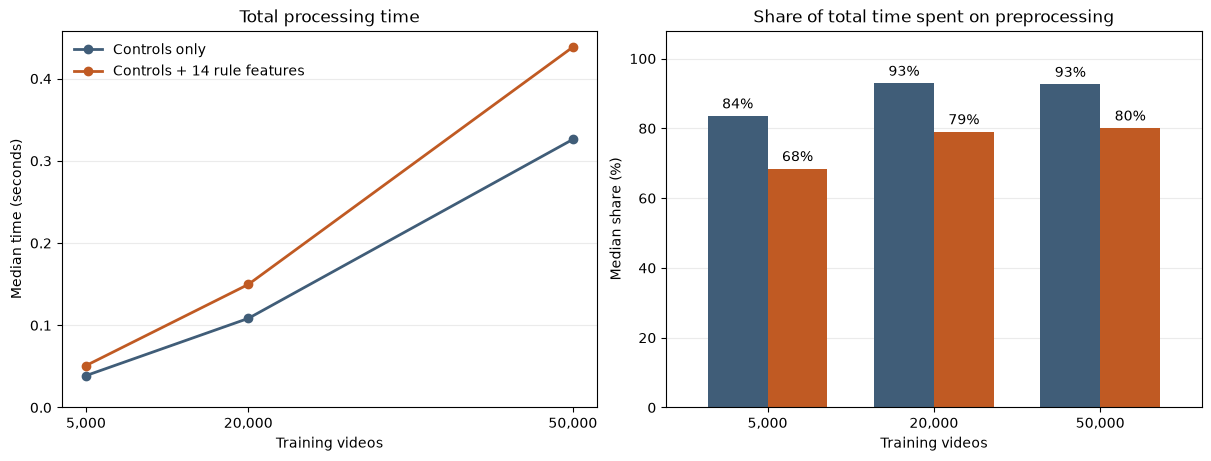

In [10]:
# Left chart: median total time across the six runs for each model and size.
total_time = timing_summary["Total (s)"].unstack("Model").sort_index()

# Right chart: calculate the preprocessing share within each run first,
# then take the median share across the six runs.
preprocessing_share = (
    timings.assign(
        preprocessing_pct=100 * timings["Preprocessing (s)"] / timings["Total (s)"]
    )
    .groupby(["Training videos", "Model"])["preprocessing_pct"]
    .median()
    .unstack("Model")
    .sort_index()
)

# Use the same model order and colors in both charts.
model_names = ["Controls only", "Controls + 14 rule features"]
colors = ["#405D78", "#C05A23"]

fig, (ax_time, ax_share) = plt.subplots(
    1, 2, figsize=(12, 4.5), constrained_layout=True
)

# 1. Plot total time against the actual number of training videos.
for model_name, color in zip(model_names, colors):
    ax_time.plot(
        total_time.index,
        total_time[model_name],
        marker="o",
        linewidth=2,
        color=color,
        label=model_name,
    )

ax_time.set_title("Total processing time")
ax_time.set_xlabel("Training videos")
ax_time.set_ylabel("Median time (seconds)")
ax_time.set_xticks(total_time.index, [f"{n:,}" for n in total_time.index])
ax_time.set_ylim(bottom=0)
ax_time.grid(axis="y", alpha=0.25)
ax_time.legend(frameon=False)

# 2. Compare the percentage of total time spent on preprocessing.
preprocessing_share[model_names].plot.bar(
    ax=ax_share,
    color=colors,
    width=0.72,
    legend=False,
    rot=0,
)

# Print the measured percentage above each bar.
for bars in ax_share.containers:
    ax_share.bar_label(bars, fmt="%.0f%%", padding=3)

ax_share.set_title("Share of total time spent on preprocessing")
ax_share.set_xlabel("Training videos")
ax_share.set_ylabel("Median share (%)")
ax_share.set_xticks(
    range(len(preprocessing_share)),
    [f"{n:,}" for n in preprocessing_share.index],
)
ax_share.set_ylim(0, 108)  # Leave room above the bars for percentage labels.
ax_share.set_yticks(range(0, 101, 20))
ax_share.grid(axis="y", alpha=0.25)
ax_share.set_axisbelow(True)

plt.show()

### Scaling result

At 50,000 training videos, median preprocessing and fitting time increased
from 0.256 seconds with controls alone to 0.355 seconds with the 14 title
features. The additional cost was about 0.10 seconds per fit.

Preprocessing took the most time in both models. If we tested several Ridge
regularization settings on the same training rows and features, we could
preprocess the data once and reuse the transformed matrix for each fit.